## Questions to Answer
1. Which restaurant type (Dining, Cafes, Buffet, Other) is the most common?
2. Do restaurants with online ordering get higher ratings?
3. Does a higher cost for two mean a higher rating?
4. Are there outliers in votes or cost?
5. Do restaurants with more votes tend to have higher ratings?

In [1]:
import pandas as pd 
import numpy as np

df=pd.read_csv("C:/Users/ACER/Downloads/Zomato-data-.csv")
df.head()

# Rename columns

df=df.rename(columns={
    "approx_cost(for two people)":"cost_for_two",
    "listed_in(type)":"category"
})

# Clean rating

df['rate']=df["rate"].str.replace(" ","").str.split("/").str[0].astype(float)

df.info()
df.isnull().sum()
df.duplicated().sum()

df.describe()



<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          148 non-null    str    
 1   online_order  148 non-null    str    
 2   book_table    148 non-null    str    
 3   rate          148 non-null    float64
 4   votes         148 non-null    int64  
 5   cost_for_two  148 non-null    int64  
 6   category      148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


,rate,votes,cost_for_two
count,148.000000,148.000000,148.000000
mean,3.633108,264.810811,418.243243
std,0.402271,653.676951,223.085098
min,2.600000,0.000000,100.000000
25%,3.300000,6.750000,200.000000
50%,3.700000,43.500000,400.000000
75%,3.900000,221.750000,600.000000
max,4.600000,4884.000000,950.000000


Rating (rate)

Mean 3.63 and median 3.70, so ratings are fairly symmetrical.
Range is 2.6 to 4.6, and std is only 0.40, so most restaurants rate between 3.3 and 3.9.

Votes

Mean is 265 but the median is only 43.5. The mean is far above the median, so the data is right-skewed.
Max is 4,884 against a 75th percentile of 222, so there are likely outliers.
Min is 0, so some restaurants have no votes. Their ratings may be unreliable.

Cost for two (cost_for_two)

Mean 418, median 400, range ₹100 to ₹950.
The mean and median are close, so there are probably no extreme outliers.

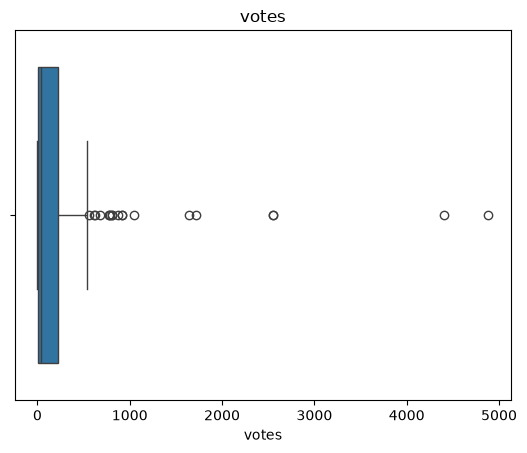

votes outliers: 19


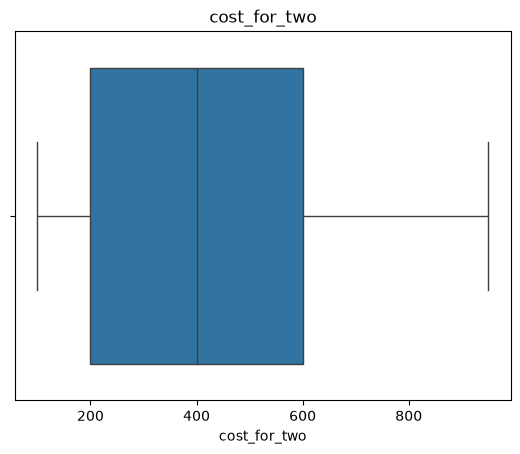

cost_for_two outliers: 0


book_table
No     140
Yes      8
Name: count, dtype: int64

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in ["votes", "cost_for_two"]:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    out = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(col, "outliers:", len(out))

df["category"].value_counts()
df["online_order"].value_counts(normalize=True) * 100
df["book_table"].value_counts()

### Outlier Analysis

**Votes**
- The boxplot shows a strongly right-skewed distribution. Most restaurants have fewer than about 220 votes (75th percentile).
- The IQR method flags **19 outliers**. Any value above about 544 votes is treated as an outlier.
- The largest values are about 4,400 and 4,884 votes.
- **Decision: keep them.** They are real, very popular restaurants, not data entry errors. Removing them would hide an important pattern.
- Because of the skew, the median (43.5) describes a typical restaurant better than the mean (265).

**Cost for two**
- **0 outliers.** The values range from ₹100 to ₹950.
- The median is about ₹400 and the distribution is fairly balanced.
- No treatment is needed.

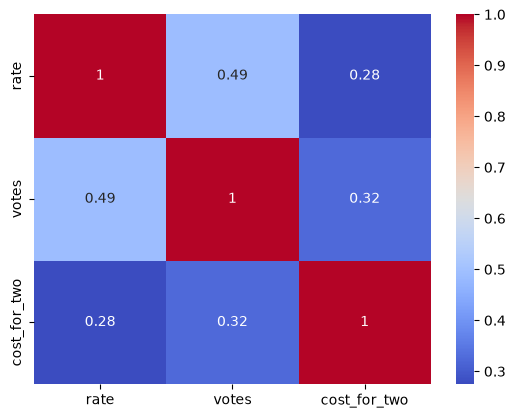

In [4]:
corr = df[["rate", "votes", "cost_for_two"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

### Correlation Analysis

- **Rate vs Votes (0.49):** moderate positive correlation. Restaurants with more votes tend to have higher ratings.
- **Rate vs Cost for two (0.28):** weak positive correlation. Higher-priced restaurants are only slightly better rated.
- **Votes vs Cost for two (0.32):** weak positive correlation.
- All correlations are positive, and none is strong (above 0.7).
- **Note:** correlation does not prove causation. Votes are also skewed by outliers, which can affect the correlation value.

In [5]:
df.groupby("category")[["rate", "votes", "cost_for_two"]].mean().round(2)
df.groupby("online_order")["rate"].mean().round(2)

online_order
No     3.49
Yes    3.86
Name: rate, dtype: float64

### Trends and Patterns

- Restaurants that accept **online orders** have a higher average rating (**3.86**) than those that don't (**3.49**).
- This difference is tested statistically in the next section.
- (Add 1-2 lines about categories after you send me the category output.)

In [8]:
from scipy import stats

yes = df[df["online_order"] == "Yes"]["rate"]
no = df[df["online_order"] == "No"]["rate"]

print(yes.mean(), no.mean())
print(stats.ttest_ind(yes, no, equal_var=False))

3.8586206896551727 3.4877777777777768
TtestResult(statistic=np.float64(6.010545939714545), pvalue=np.float64(2.2422446085481642e-08), df=np.float64(114.69761465699061))


### Hypothesis Test: Online Ordering vs Rating

- **Question:** Do restaurants with online ordering have higher ratings?
- **H0 (null):** There is no difference in average rating between restaurants with and without online ordering.
- **H1 (alternative):** The average rating differs between the two groups.
- **Test used:** Welch's independent t-test (does not assume equal variances), significance level 0.05.

In [7]:
%pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.3/37.4 MB 3.9 MB/s eta 0:00:10
   -- ------------------------------------- 2.1/37.4 MB 3.8 MB/s eta 0:00:10
   --- ------------------------------------ 3.1/37.4 MB 4.0 MB/s eta 0:00:09
   ---- ----------------------------------- 3.9/37.4 MB 4.2 MB/s eta 0:00:09
   ---- ----------------------------------- 4.2/37.4 MB 4.0 MB/s eta 0:00:09
   ---- ----------------------------------- 4.2/37.4 MB 4.0 MB/s eta 0:00:09
   ---- ----------------------------------- 4.2/37.4 MB 4.0 MB/s eta 0:00:09
   ----- ---------------------------------- 4.7/37.4 MB 2.5 MB/s eta 0:00:14
   ----- ---------------------------------- 5.2/37.4 MB 2.5 MB/s eta 0:00:13
   ------ --------------------------------- 6.0/37.4 MB 2.7 MB/s eta 0:00:12
   ------ --------------------------------- 6.0/37.4 MB 2.7 MB/s eta 0:00:12
   ------ ---


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
df.groupby("category")[["rate", "votes", "cost_for_two"]].mean().round(2)


,rate,votes,cost_for_two
category,,,
Buffet,3.84,432.57,671.43
Cafes,3.77,279.74,545.65
Dining,3.57,185.12,357.27
other,3.91,1170.88,668.75


### Trends by Restaurant Category

| Category | Avg Rating | Avg Votes | Avg Cost for Two (₹) |
|---|---|---|---|
| Buffet | 3.84 | 432.57 | 671.43 |
| Cafes | 3.77 | 279.74 | 545.65 |
| Dining | 3.57 | 185.12 | 357.27 |
| Other | 3.91 | 1170.88 | 668.75 |

- **Dining** has the lowest average rating (3.57) and the lowest cost (about ₹357), but it is by far the largest category.
- **Buffet** and **Other** have the highest costs (about ₹670) and high ratings (3.84 and 3.91).
- **Other** has the highest average votes (1,170.88). This is likely because a few very popular restaurants, such as the outliers found earlier, pull the average up.
- Higher-cost categories tend to have higher ratings, which is consistent with the weak positive correlation (0.28) between cost and rating.
- **Caution:** Buffet (7 restaurants) and Other (8 restaurants) are very small groups, so their averages are less reliable than Dining (110) and Cafes (23).

In [12]:
df["category"].value_counts()

category
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64

## Findings and Conclusion

### Answers to the Questions
1. **Most common type:** Dining, with 110 of 148 restaurants (about 74%). Cafes follow with 23.
2. **Online ordering and rating:** Restaurants with online ordering have a higher average rating (3.86) than those without (3.49). A Welch t-test gives p ≈ 2.2 × 10⁻⁸, so the difference is statistically significant.
3. **Cost and rating:** There is a weak positive correlation (0.28). Higher-priced restaurants are only slightly better rated.
4. **Outliers:** Votes have 19 outliers (kept, as they are genuinely popular restaurants). Cost has none.
5. **Votes and rating:** There is a moderate positive correlation (0.49). Restaurants with more votes tend to have higher ratings.

### Key Insights
- Dining dominates the dataset but has the lowest average rating (3.57) and lowest cost (about ₹357).
- Online ordering is the clearest factor linked to higher ratings in this data.
- Votes are highly right-skewed (median 43.5 vs mean 265), so the median is a better measure of a typical restaurant.
- Ratings are tightly clustered (most between 3.3 and 3.9).

### Data Issues Fixed (Issues Log)
| Issue | Fix |
|---|---|
| `rate` stored as text ("4.1/5") | Split on "/" and converted to float |
| One rating had a typo ("3.8 /5") | Removed spaces before converting |
| Column names had brackets and spaces | Renamed to `cost_for_two` and `category` |
| Repeated restaurant names (San Churro Cafe, Onesta, CAFE NOVA) | Reviewed; they appear under different categories (write here whether you kept or dropped them) |
| Votes highly skewed, 19 outliers | Kept as genuine data; used the median for typical values |
| Missing values | None found |

### Limitations
- Small dataset (148 rows), so results may not generalise.
- Only 8 restaurants offer table booking, and Buffet (7) and Other (8) are very small groups.
- No location, cuisine or date columns.
- Correlation and the t-test show association, not causation.

### Next Steps
- Visualise these findings in a dashboard (Task 3).
- Test with a larger Zomato dataset that includes cuisine and location.
- Try a non-parametric test (Mann-Whitney U) as a robustness check, given the skewed data.